<a href="https://colab.research.google.com/github/jonathan-ha1/Problem-Set-1/blob/main/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

A single parent recently hired at the company on an hourly wage, raising a four-year-old who attends full-time daycare. They rent a two-bedroom apartment and commute to work by car, so most of their monthly budget goes to rent and childcare, followed by groceries, gas, and car insurance.


> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [146]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent",          "Price_2019": 1300, "Price_2024": 1650, "weight": 0.38},
    {"Item": "Childcare",     "Price_2019": 800,  "Price_2024": 1000, "weight": 0.20},
    {"Item": "Groceries",     "Price_2019": 500,  "Price_2024": 625,  "weight": 0.16},
    {"Item": "Gas",           "Price_2019": 2.60, "Price_2024": 3.30, "weight": 0.08},
    {"Item": "Car insurance", "Price_2019": 120,  "Price_2024": 175,  "weight": 0.07},
    {"Item": "Electricity",   "Price_2019": 115,  "Price_2024": 145,  "weight": 0.06},
    {"Item": "Phone",         "Price_2019": 65,   "Price_2024": 62,   "weight": 0.05},
]

In [147]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [148]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    return sum(item["weight"] * item[current_key] / item[base_key] for item in basket) * 100

In [149]:
# 1. the unweighted average price change across categories
unweighted = sum((item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100 for item in household_basket) / len(household_basket)
print("unweighted average change:", round(unweighted, 2), "%")

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
index = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted = index - 100
print("Laspeyres index:", round(index, 2))
print("weighted change:", round(weighted, 2), "%")

# 3. the gap between them
gap = weighted - unweighted
print("gap:", round(gap, 2), "percentage points")

unweighted average change: 24.45 %
Laspeyres index: 125.93
weighted change: 25.93 %
gap: 1.48 percentage points


**Why do the two differ, and which would you defend to the client?**

The unweighted average of 24.45% counts every category equally, so the phone plan’s 4.6% drop pulls it down as much as a change in rent would, while the Laspeyres index of 25.93% weights each price change by its share of the 2019 budget, which lets rent and childcare, the two largest expenses, drive the result. I would defend the weighted index to the client because it measures how much more it costs this household to buy the same things it bought in 2019, whereas the unweighted average mostly reflects which categories happened to be included.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [150]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CUSR0000SETB01", "CUSR0000SEEB"]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | It is the official benchmark the client is comparing against.|It reflects what the average city household buys, not this family’s spending |
| `CUSR0000SEHA` | It tracks the rent that renters pay, and this household rents|It is a national average that includes older leases, so it lags local rents |
| `CUSR0000SAF11` |It tracks grocery prices, which are a major expense for this household.  |It does not reflect what this family actually buys or how they switch products.  |
| `CUSR0000SETA02` |The household depends on a car to commute | They do not buy a car every year, and the basket has no car purchase line|
| `CUSR0000SETB01` |It tracks the gas used for the daily commute | It does not capture regional gas price differences.|
| `CUSR0000SEEB` | It tracks childcare costs for the household's four-year-old. | It includes tuition and school fees, which this household does not pay, and it is a national average. |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [151]:
# Rebase to 2019 = 100

def load_fred(series_id, start="1947-01-01", end=None):
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

cpi = load_fred("CPIAUCSL", start="2019-01-01")
rent = load_fred("CUSR0000SEHA", start="2019-01-01")
food = load_fred("CUSR0000SAF11", start="2019-01-01")
used_cars = load_fred("CUSR0000SETA02", start="2019-01-01")
gas = load_fred("CUSR0000SETB01", start="2019-01-01")
childcare = load_fred("CUSR0000SEEB", start="2019-01-01")

cpi_r = cpi / cpi.loc[cpi.index.year == 2019].mean() * 100
rent_r = rent / rent.loc[rent.index.year == 2019].mean() * 100
food_r = food / food.loc[food.index.year == 2019].mean() * 100
used_cars_r = used_cars / used_cars.loc[used_cars.index.year == 2019].mean() * 100
gas_r = gas / gas.loc[gas.index.year == 2019].mean() * 100
childcare_r = childcare / childcare.loc[childcare.index.year == 2019].mean() * 100

print("CPI, 2024 average:", round(cpi_r.loc[cpi_r.index.year == 2024].mean(), 2))

CPI, 2024 average: 122.7


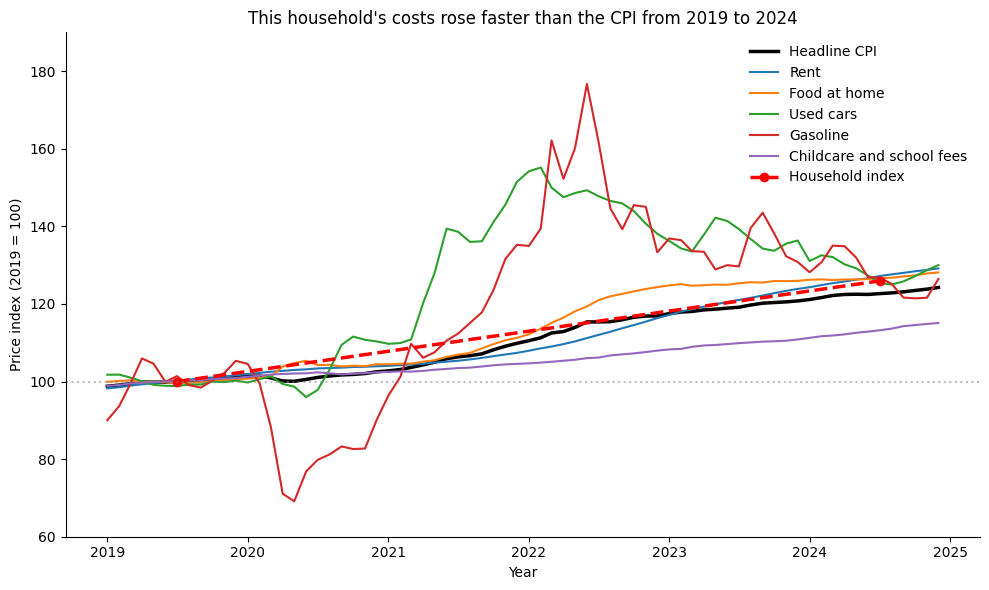

In [152]:
# One chart: every rebased series, plus your household index

household = pd.Series([100, index], index=pd.to_datetime(["2019-07-01", "2024-07-01"]))

cpi_r = cpi_r.loc["2019":"2024"]
rent_r = rent_r.loc["2019":"2024"]
food_r = food_r.loc["2019":"2024"]
used_cars_r = used_cars_r.loc["2019":"2024"]
gas_r = gas_r.loc["2019":"2024"]
childcare_r = childcare_r.loc["2019":"2024"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(cpi_r.index, cpi_r, label="Headline CPI", color="black", linewidth=2.5)
ax.plot(rent_r.index, rent_r, label="Rent")
ax.plot(food_r.index, food_r, label="Food at home")
ax.plot(used_cars_r.index, used_cars_r, label="Used cars")
ax.plot(gas_r.index, gas_r, label="Gasoline")
ax.plot(childcare_r.index, childcare_r, label="Childcare and school fees")
ax.plot(household.index, household, label="Household index", color="red", marker="o", linestyle="--", linewidth=2.5)
ax.axhline(y=100, color="gray", linestyle=":", alpha=0.5)
ax.set_ylim(60, 190)
ax.set_xlabel("Year")
ax.set_ylabel("Price index (2019 = 100)")
ax.set_title("This household's costs rose faster than the CPI from 2019 to 2024")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [153]:
# First observation, last observation, frequency and missing months, for every series
for sid in series_ids:
    s = load_fred(sid)
    grid = s.asfreq("MS")
    print(sid, "first:", s.index.min().date(), "last:", s.index.max().date(), "missing:", grid.isna().sum())
    print(grid[grid.isna()])

CPIAUCSL first: 1947-01-01 last: 2026-08-01 missing: 1
date
2025-10-01   NaN
Freq: MS, Name: CPIAUCSL, dtype: float64
CUSR0000SEHA first: 1981-01-01 last: 2026-08-01 missing: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SEHA, dtype: float64
CUSR0000SAF11 first: 1952-01-01 last: 2026-08-01 missing: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SAF11, dtype: float64
CUSR0000SETA02 first: 1953-01-01 last: 2026-08-01 missing: 0
Series([], Freq: MS, Name: CUSR0000SETA02, dtype: float64)
CUSR0000SETB01 first: 1967-01-01 last: 2026-08-01 missing: 0
Series([], Freq: MS, Name: CUSR0000SETB01, dtype: float64)
CUSR0000SEEB first: 1978-01-01 last: 2026-08-01 missing: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SEEB, dtype: float64


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| `CPIAUCSL` | 1947-01 | 2026-08 | Monthly | 1: October 2025 |
| `CUSR0000SEHA` | 1981-01 | 2026-08 | Monthly | 1: October 2025 |
| `CUSR0000SAF11` | 1952-01 | 2026-08 | Monthly | 1: October 2025 |
| `CUSR0000SETA02` | 1953-01 | 2026-08 | Monthly | 0 |
| `CUSR0000SETB01` | 1967-01 | 2026-08 | Monthly | 0 |
| `CUSR0000SEEB` | 1978-01 | 2026-08 | Monthly | 1: October 2025 |

October 2025 is missing because the 2025 government shutdown stopped the Bureau of Labor Statistics from collecting survey prices that month. Gasoline and used cars still have October values because the BLS was able to fill those in afterward from non-survey data. None of the series are missing any months between 2019 and 2024, so the household comparison is not affected.

https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi.htm

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [154]:
# Start dates side by side, and the common sample
full = pd.DataFrame({
    "CPIAUCSL": load_fred("CPIAUCSL"),
    "CUSR0000SEHA": load_fred("CUSR0000SEHA"),
    "CUSR0000SAF11": load_fred("CUSR0000SAF11"),
    "CUSR0000SETA02": load_fred("CUSR0000SETA02"),
    "CUSR0000SETB01": load_fred("CUSR0000SETB01"),
    "CUSR0000SEEB": load_fred("CUSR0000SEEB"),
})

for sid in series_ids:
    print(sid, full[sid].dropna().index.min().date())

common = full.dropna()
print("Common sample starts:", common.index.min().date())
print("Months in common sample:", len(common))
print("CPI months discarded:", len(full["CPIAUCSL"].dropna()) - len(common))

CPIAUCSL 1947-01-01
CUSR0000SEHA 1981-01-01
CUSR0000SAF11 1952-01-01
CUSR0000SETA02 1953-01-01
CUSR0000SETB01 1967-01-01
CUSR0000SEEB 1978-01-01
Common sample starts: 1981-01-01
Months in common sample: 547
CPI months discarded: 408


In [155]:
# Headline comparison: full history vs common sample
for sid in series_ids:
    s = full[sid].dropna()
    full_change = ((s.iloc[-1] / s.iloc[0]) - 1) * 100
    common_change = ((common[sid].iloc[-1] / common[sid].iloc[0]) - 1) * 100
    print(sid, "full history:", round(full_change, 1), "%  common sample:", round(common_change, 1), "%")

CPIAUCSL full history: 1455.5 %  common sample: 283.2 %
CUSR0000SEHA full history: 430.5 %  common sample: 430.5 %
CUSR0000SAF11 full history: 929.9 %  common sample: 244.0 %
CUSR0000SETA02 full history: 530.5 %  common sample: 157.4 %
CUSR0000SETB01 full history: 1212.4 %  common sample: 233.2 %
CUSR0000SEEB full history: 1509.6 %  common sample: 1121.0 %


**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample assumes the data from 1981 on is enough, so dropping 408 months of CPI and October 2025 doesn’t lose anything important. In return, every series covers the same dates.

Not restricting treats every series full history as if they started at the same time, but since CPI goes back 34 years further than rent, it makes it seem like rent barely went up next to CPI.  Comparing them over the same years, rent actually went up 430.5% while CPI went up 283.2%.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

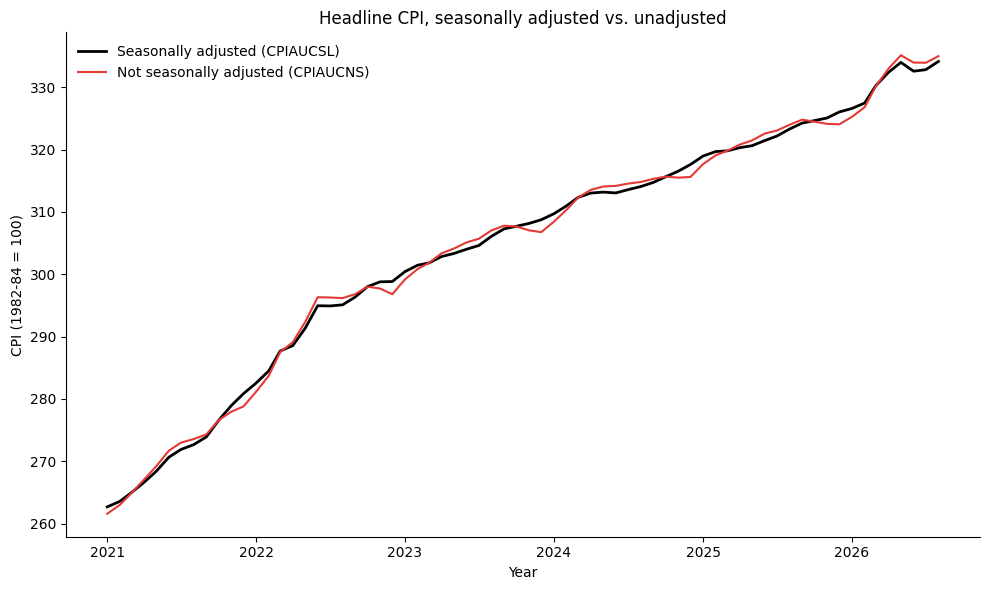

2024 average, adjusted: 313.7
2024 average, unadjusted: 313.7


In [156]:
# Seasonally adjusted vs unadjusted, last five years
sa = load_fred("CPIAUCSL").loc["2021":]
nsa = load_fred("CPIAUCNS").loc["2021":]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(sa.index, sa, label="Seasonally adjusted (CPIAUCSL)", color="black", linewidth=2)
ax.plot(nsa.index, nsa, label="Not seasonally adjusted (CPIAUCNS)", color="#E53935", linewidth=1.5)
ax.set_xlabel("Year")
ax.set_ylabel("CPI (1982-84 = 100)")
ax.set_title("Headline CPI, seasonally adjusted vs. unadjusted")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
print("2024 average, adjusted:", round(sa.loc[sa.index.year == 2024].mean(), 1))
print("2024 average, unadjusted:", round(nsa.loc[nsa.index.year == 2024].mean(), 1))

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines is the seasonal pattern, which means each year, the unadjusted series runs slightly above the adjusted series in the spring and summer and falls below it near the end of the year. The adjusted series removes this pattern using an estimate made by someone else, which is the decision already made for us. Because this brief compares full years, the seasonal swings cancel out, and both series have the same 2024 average of 313.7. The unadjusted series belongs in the brief because it reflects the prices workers actually paid, without an estimated adjustment removed. Although my Phase 2 chart and comparison used the seasonally adjusted series, it does not change anything because the comparison is based on full-year averages, and the adjusted and unadjusted 2024 averages are both 313.7. Switching to the unadjusted series would give the same result.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Base Laspeyres index: 125.93

         Item  base_weight  relative  others_avg_relative  pts_per_+0.10_weight  range_over_sweep
        Phone         0.05     0.954                1.275                -3.215            16.075
Car insurance         0.07     1.458                1.244                 2.140            10.702
         Rent         0.38     1.269                1.253                 0.161             0.803
    Childcare         0.20     1.250                1.262                -0.116             0.580
    Groceries         0.16     1.250                1.261                -0.110             0.552
          Gas         0.08     1.269                1.258                 0.108             0.541
  Electricity         0.06     1.261                1.259                 0.017             0.085


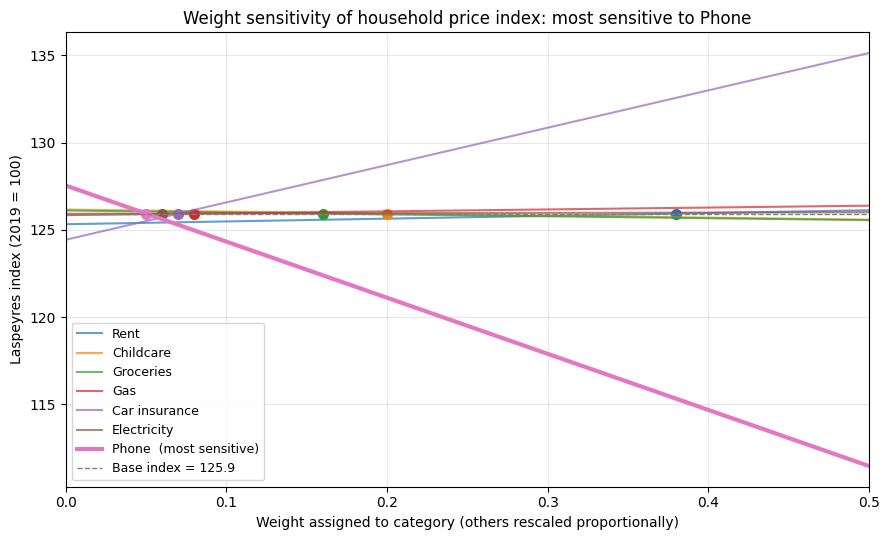

In [157]:
# Paste the AI's code here, run it, and correct it where it is wrong
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Setup -------------------------------------------------------------
df = pd.DataFrame(household_basket)

# Normalise base weights so they sum to 1 (guards against weights given
# as percentages or slightly-off shares).
df["weight"] = df["weight"] / df["weight"].sum()

# Price relatives: a Laspeyres index is just the weighted mean of these.
df["relative"] = df["Price_2024"] / df["Price_2019"]

rel = df["relative"].to_numpy()
w0 = df["weight"].to_numpy()
n = len(df)

base_index = 100 * np.dot(w0, rel)

# --- Sweep -------------------------------------------------------------
grid = np.linspace(0, 0.5, 51)
sweep = {}
rows = []

for k, item in enumerate(df["Item"]):
    mask = np.arange(n) != k

    # WHY RENORMALISE: weights in a Laspeyres index must sum to 1. If we
    # raised one category's weight without shrinking the others, the
    # "index" would mix a real price change with an artificial change in
    # total basket size, and the curve would rise even if no prices
    # moved. Scaling the other weights by (1 - w) keeps the basket a
    # proper set of shares. Keeping them *in proportion* (fixed relative
    # shares among themselves) isolates the effect of this one category
    # instead of silently reshuffling the rest.
    other_share = w0[mask] / w0[mask].sum()
    R_other = np.dot(other_share, rel[mask])   # avg relative of the rest

    # Index along the sweep: w * r_k + (1 - w) * R_other
    sweep[item] = 100 * (grid * rel[k] + (1 - grid) * R_other)

    # Sensitivity = slope of the line, in index points per +0.10 of weight.
    # WHAT HIGH SENSITIVITY MEANS: the headline number depends heavily on
    # how much weight this one category gets. Because the weight is an
    # estimate (survey data, a client assumption), the headline then
    # carries that estimate's uncertainty. A small error in this weight
    # moves the result noticeably, and the index is really a statement
    # about this category's price change rather than "the household's"
    # cost of living.
    slope_per_tenth = 100 * (rel[k] - R_other) / 10
    rows.append({
        "Item": item,
        "base_weight": w0[k],
        "relative": rel[k],
        "others_avg_relative": R_other,
        "pts_per_+0.10_weight": slope_per_tenth,
        "range_over_sweep": abs(slope_per_tenth) * 5,   # 0 -> 0.5
    })

sens = (pd.DataFrame(rows)
          .assign(abs_slope=lambda d: d["pts_per_+0.10_weight"].abs())
          .sort_values("abs_slope", ascending=False)
          .drop(columns="abs_slope"))

print(f"Base Laspeyres index: {base_index:.2f}\n")
print(sens.round(3).to_string(index=False))
top = sens.iloc[0]["Item"]

# --- Chart -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

for k, item in enumerate(df["Item"]):
    is_top = item == top
    line, = ax.plot(grid, sweep[item],
                    linewidth=3 if is_top else 1.5,
                    alpha=1 if is_top else 0.7,
                    label=f"{item}" + ("  (most sensitive)" if is_top else ""))
    # Mark where each category sits today (its base weight), if in range.
    if w0[k] <= 0.5:
        ax.plot(w0[k], base_index, marker="o", color=line.get_color(),
                markersize=7)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=1,
           label=f"Base index = {base_index:.1f}")
ax.set_xlabel("Weight assigned to category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Weight sensitivity of household price index: "
             f"most sensitive to {top}")
ax.set_xlim(0, 0.5)
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()

In [158]:
print("AI's base index:", round(base_index, 2))
print("My laspeyres():", round(laspeyres(household_basket, "Price_2019", "Price_2024"), 2))

for k, item in enumerate(df["Item"]):
    print(item, "index at its actual weight:", round(sweep[item][int(round(w0[k] * 100))], 2))

AI's base index: 125.93
My laspeyres(): 125.93
Rent index at its actual weight: 125.93
Childcare index at its actual weight: 125.93
Groceries index at its actual weight: 125.93
Gas index at its actual weight: 125.93
Car insurance index at its actual weight: 125.93
Electricity index at its actual weight: 125.93
Phone index at its actual weight: 125.93


**What did the model get wrong, or get right in a way you had to check? Show the check.**

When the code changes one category’s weight, it has to rescale the others so the weights still add up to 1. If that step were wrong, every result on the chart would be off. To check it, I first confirmed that the code’s base index of 125.93 matched what my own laspeyres() function gives. Then I looked at each category’s line at its actual weight, like Rent at 0.38, and all seven came back to 125.93. That shows the other weights were rescaled correctly. The code also worked with all seven of my categories, even though the prompt said six.

### AI Transcript

**Model:** Claude Opus 5.5 &nbsp; **Date:** October 9th, 2026


*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

```
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.
```

MODEL'S REPLY


I can’t tell you which category dominates yet because I don’t have your household_basket numbers. Run the script below and the printed table will name it. The math also tells you what to expect before you run anything.

Why the answer is predictable. A Laspeyres index is a weighted average of price relatives, rᵢ = Price_2024 / Price_2019. If you set category k’s weight to w and scale the others proportionally, the index becomes:

I(w) = 100 × [ w·r_k + (1 − w)·R₋ₖ ]

Here R₋ₖ is the weighted average relative of the other five categories. That’s a straight line in w with slope 100 × (r_k − R₋ₖ). So the category the index is most sensitive to is the one whose price change differs most from everything else. It is not necessarily the biggest category. A small category with an extreme price change can matter more than a large one that moved with the pack.

python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Setup -------------------------------------------------------------
df = pd.DataFrame(household_basket)

# Normalise base weights so they sum to 1 (guards against weights given
# as percentages or slightly-off shares).
df["weight"] = df["weight"] / df["weight"].sum()

# Price relatives: a Laspeyres index is just the weighted mean of these.
df["relative"] = df["Price_2024"] / df["Price_2019"]

rel = df["relative"].to_numpy()
w0 = df["weight"].to_numpy()
n = len(df)

base_index = 100 * np.dot(w0, rel)

# --- Sweep -------------------------------------------------------------
grid = np.linspace(0, 0.5, 51)
sweep = {}
rows = []

for k, item in enumerate(df["Item"]):
    mask = np.arange(n) != k

    # WHY RENORMALISE: weights in a Laspeyres index must sum to 1. If we
    # raised one category's weight without shrinking the others, the
    # "index" would mix a real price change with an artificial change in
    # total basket size, and the curve would rise even if no prices
    # moved. Scaling the other weights by (1 - w) keeps the basket a
    # proper set of shares. Keeping them *in proportion* (fixed relative
    # shares among themselves) isolates the effect of this one category
    # instead of silently reshuffling the rest.
    other_share = w0[mask] / w0[mask].sum()
    R_other = np.dot(other_share, rel[mask])   # avg relative of the rest

    # Index along the sweep: w * r_k + (1 - w) * R_other
    sweep[item] = 100 * (grid * rel[k] + (1 - grid) * R_other)

    # Sensitivity = slope of the line, in index points per +0.10 of weight.
    # WHAT HIGH SENSITIVITY MEANS: the headline number depends heavily on
    # how much weight this one category gets. Because the weight is an
    # estimate (survey data, a client assumption), the headline then
    # carries that estimate's uncertainty. A small error in this weight
    # moves the result noticeably, and the index is really a statement
    # about this category's price change rather than "the household's"
    # cost of living.
    slope_per_tenth = 100 * (rel[k] - R_other) / 10
    rows.append({
        "Item": item,
        "base_weight": w0[k],
        "relative": rel[k],
        "others_avg_relative": R_other,
        "pts_per_+0.10_weight": slope_per_tenth,
        "range_over_sweep": abs(slope_per_tenth) * 5,   # 0 -> 0.5
    })

sens = (pd.DataFrame(rows)
          .assign(abs_slope=lambda d: d["pts_per_+0.10_weight"].abs())
          .sort_values("abs_slope", ascending=False)
          .drop(columns="abs_slope"))

print(f"Base Laspeyres index: {base_index:.2f}\n")
print(sens.round(3).to_string(index=False))
top = sens.iloc[0]["Item"]

# --- Chart -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

for k, item in enumerate(df["Item"]):
    is_top = item == top
    line, = ax.plot(grid, sweep[item],
                    linewidth=3 if is_top else 1.5,
                    alpha=1 if is_top else 0.7,
                    label=f"{item}" + ("  (most sensitive)" if is_top else ""))
    # Mark where each category sits today (its base weight), if in range.
    if w0[k] <= 0.5:
        ax.plot(w0[k], base_index, marker="o", color=line.get_color(),
                markersize=7)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=1,
           label=f"Base index = {base_index:.1f}")
ax.set_xlabel("Weight assigned to category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Weight sensitivity of household price index: "
             f"most sensitive to {top}")
ax.set_xlim(0, 0.5)
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()

How to read the output. The steepest line on the chart is the dominant category. The dots show where each category’s actual weight sits on its line. All of the dots fall on the dashed base line, because at its real weight every category reproduces the base index. The pts_per_+0.10_weight column is the number to quote: “if this category’s share were 10 percentage points higher, the index would be X points higher.”

What to tell a client once you know the category:

State the dependency plainly. For example: “Your headline figure of [base index] is driven mainly by [category], whose prices rose [r_k − 1]% against about [R₋ₖ − 1]% for everything else.”
Give a range, not a single number. Report the index under plausible alternative weights for that category, e.g. ±0.05 around the base weight. A single number implies more precision than the weights support.
Show the index excluding that category. This lets them see the “everything else” story separately.
Defend or flag the weight source. If the dominant category’s weight comes from a rough assumption rather than solid spending data, that is the biggest risk in the deliverable. Say so.
Note the standard Laspeyres caveat. A fixed 2019 basket ignores substitution. If households shifted away from the category whose price spiked, the index overstates their real cost increase, and that bias is concentrated in exactly the category you’ve found.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

From 2019 to 2024, living costs for a single parent working an hourly job at the employer went up about 25.9%, compared to 22.7% for the CPI. That means the CPI doesn’t overstate what these workers face. If anything, it understates it by about 3 points.
The household used  is a single parent who rents a two-bedroom apartment, drives to work, and has a kid in full-time daycare. Rent and daycare are more than half of their budget, and both went up faster than prices in general. The CPI is based on what the average household buys, which looks pretty different from this budget.

The employer could be right about some workers. If someone doesn’t spend much on rent or daycare, their costs probably went up less than the CPI. But the workers a starting wage is meant to attract are more like this household, and their costs went up faster than the CPI.

The confidence level would be moderate because the result held up when the budget shares were changed around, and the official data didn’t have any missing months between 2019 and 2024. The weak spots are that the 2019 and 2024 prices for this household are estimates, not the employer’s actual numbers, and the official data is national, not local. A good idea would be to check local rent and daycare prices before settling on a wage.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub